In [ ]:
!pip install tensorflow

In [ ]:
!pip install nltk
!pip install contractions
!pip install wordcloud
!pip install scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import re
import nltk
from nltk.corpus import stopwords
from bs4 import BeautifulSoup
from wordcloud import WordCloud, STOPWORDS
from sklearn.model_selection import train_test_split #Для разделения на тренировочные и тестовые
#from keras.preprocessing import text, sequence # Для создания объекта "слова => числа"
from tensorflow.keras.preprocessing import text, sequence

import contractions

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
df_news = pd.read_csv('news.csv', engine='python', encoding='utf-8')

In [ ]:
print(df_news.shape)
df_news.head()

(6335, 4)


,Unnamed: 0,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,REAL
3,10142,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,REAL


In [ ]:
df_news.sample(5)

,Unnamed: 0,title,text,label
218,3602,Authorities search for clues after raid thwart...,Belgian authorities were searching for clues e...,REAL
4379,617,Bobby Jindal governing like it's 2016,Ohio Democrat Tim Ryan does a lot of media but...,REAL
730,5177,Bernie's swan song begins,**Want FOX News Halftime Report in your inbox ...,REAL
3186,7312,Peter Thiel On Trump,Recipient Email => \nI earnestly recommend t...,FAKE
4121,6776,Project Veritas Undercover Journalist in Full ...,We Are Change \nIn this latest Project Veritas...,FAKE


In [ ]:
df_news.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  6335 non-null   int64 
 1   title       6335 non-null   object
 2   text        6335 non-null   object
 3   label       6335 non-null   object
dtypes: int64(1), object(3)
memory usage: 198.1+ KB


In [ ]:
df_news.label.value_counts()

,count
label,
REAL,3171
FAKE,3164


In [ ]:
df_news.duplicated().sum()

np.int64(0)

In [ ]:
news_copy = df_news.copy()

In [ ]:
news_copy['label'] = news_copy['label'].replace({'REAL' : 0, 'FAKE' : 1})

/tmp/ipykernel_1523/2401808661.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  news_copy['label'] = news_copy['label'].replace({'REAL' : 0, 'FAKE' : 1})


In [ ]:
news_copy.drop('Unnamed: 0', axis=1, inplace=True)

In [ ]:
news_copy.head()

,title,text,label
0,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fello...",1
1,Watch The Exact Moment Paul Ryan Committed Pol...,Google Pinterest Digg Linkedin Reddit Stumbleu...,1
2,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Mon...,0
3,Bernie supporters on Twitter erupt in anger ag...,"— Kaydee King (@KaydeeKing) November 9, 2016 T...",1
4,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners...,0


# Basic EDA

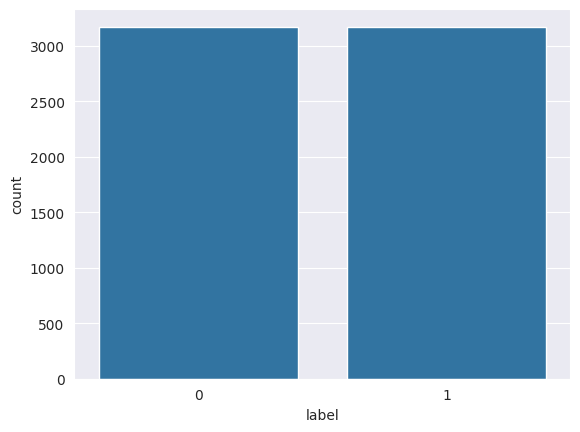

In [ ]:
sns.set_style("darkgrid")
sns.countplot(x = 'label', data=news_copy)
plt.show()

In [ ]:
news_copy.isna().sum()

,0
title,0
text,0
label,0


In [ ]:
stop_words = set(stopwords.words('english'))

In [ ]:
def clean_html(text): #чистка от html-тегов
    soup = BeautifulSoup(text, 'html.parser')
    return soup.get_text()

def remove_square_brackets(text): # Удаление квадратных скобок
    return re.sub(r'\[[^]]*\]', '', text)

def clean_url(text): #чистка url
    return re.sub(r'http\S+', '', text)
    return re.sub(r'https?://\S+', '', text) # добавлено для надёжности

def text_lower(text): #приводим к нижнему регистру
    return text.lower()

#Опционально
#def contrac(text): # don't => do not
    #return ontractions.fix(text)

def clean_Nword(text): # удаляем всё, что не ялвяется словами
    return re.sub('[^a-zA-Z0-9\s]', '', text)

def probel(text): #удаляем лишние пробелы между словами
    return re.sub('\s+', ' ', text)

def remove_stopwords(text):
    # после удаления пунктуации можно разбивать по пробелам
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return ' '.join(words)

<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:23: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:23: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1523/214926097.py:20: SyntaxWarning: invalid escape sequence '\s'
  return re.sub('[^a-zA-Z0-9\s]', '', text)
/tmp/ipykernel_1523/214926097.py:23: SyntaxWarning: invalid escape sequence '\s'
  return re.sub('\s+', ' ', text)


In [ ]:
def preprocess(text):
    text = clean_html(text)
    text = remove_square_brackets(text)
    text = clean_url(text)
    text = text_lower(text)
    text = clean_Nword(text)
    text = probel(text)
    text = remove_stopwords(text)
    return text

In [ ]:
news_copy['text'] = news_copy['text'].apply(preprocess)

# Облако слов для реальных и фейковых новостей

(np.float64(-0.5), np.float64(1599.5), np.float64(799.5), np.float64(-0.5))

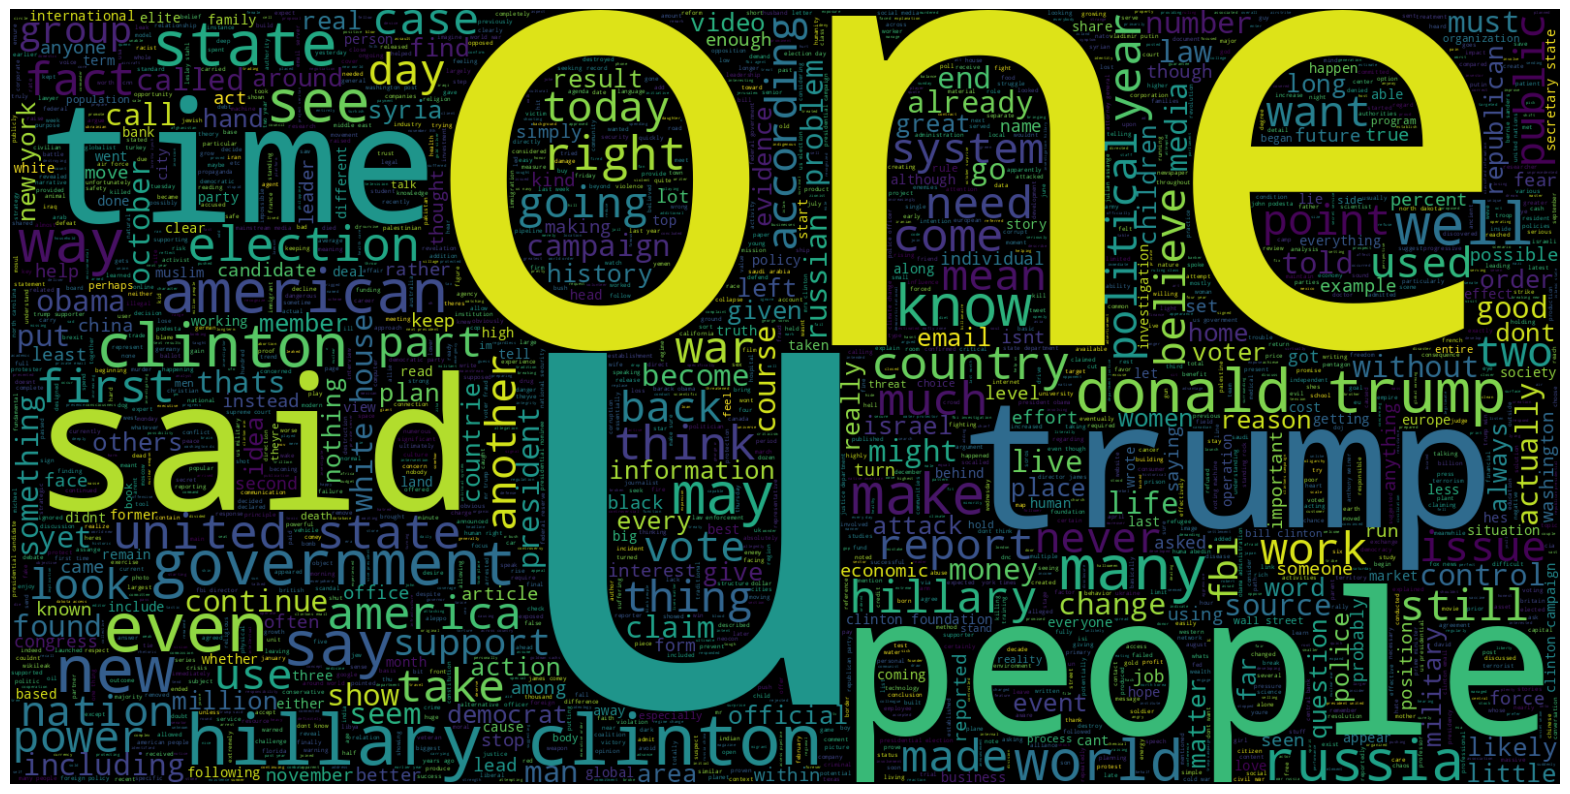

In [ ]:
plt.figure(figsize= (20, 20))

# topwords = STOPWORDS - можно добавить доп.параметр, но не имеет смысла в данном случае при предварительной очистке данных

wc = WordCloud(max_words = 2000 , width = 1600 , height = 800).generate(" ".join(news_copy[news_copy.label == 1].text))
plt.imshow(wc , interpolation = 'bilinear')
plt.axis('off')

(np.float64(-0.5), np.float64(1599.5), np.float64(799.5), np.float64(-0.5))

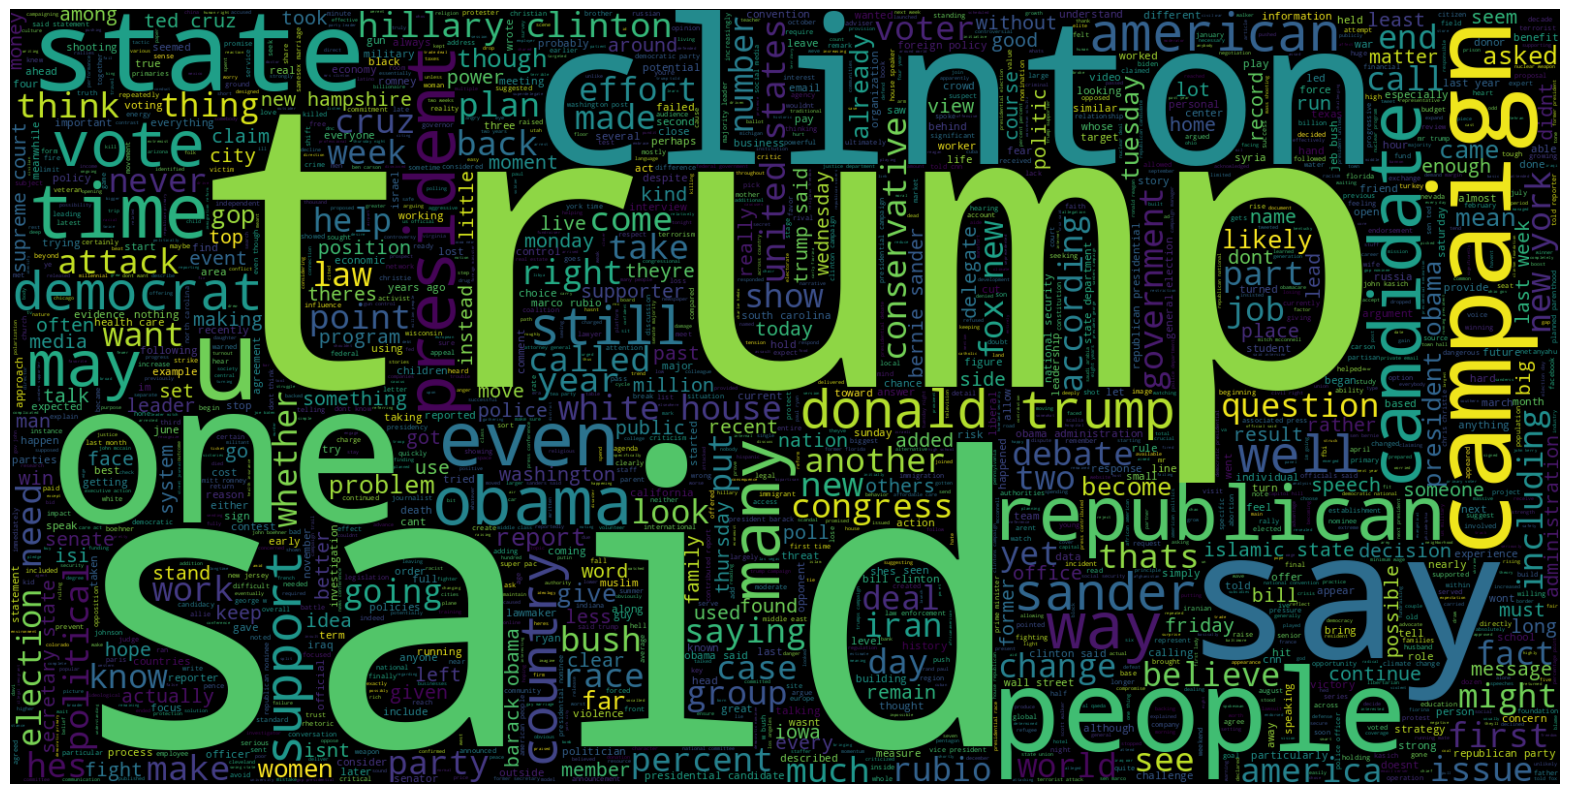

In [ ]:
plt.figure(figsize= (20, 20))

wc = WordCloud(max_words = 2000 , width = 1600 , height = 800).generate(" ".join(news_copy[news_copy.label == 0].text))
plt.imshow(wc , interpolation = 'bilinear')
plt.axis('off')

# Corpus

In [ ]:
from collections import Counter

In [ ]:
def func(text):
    words = []
    for i in text:
        for j in i.split():
            words.append(j)
    return words

result = func(news_copy.text)

In [ ]:
corpus = Counter(result)
most_common = corpus.most_common(10)
most_common = dict(most_common)
most_common

{'said': 21154,
 'trump': 18279,
 'clinton': 14371,
 'would': 12610,
 'us': 12444,
 'people': 11280,
 'one': 11150,
 'new': 9196,
 'state': 8240,
 'also': 8189}

# Train Test split

In [ ]:
X_train, X_test, y_train, y_test= train_test_split(news_copy.text, news_copy.label, random_state = 420) # Делит выборку, на тестовую и обучающую.
# random_state = 420 - зерно случайности, число может быть любым
# test_size = доп.параметр, поределющий соотношение двух выборок, по умолчанию равные 0.25 - тестовая, 0.75 - обучающие

In [ ]:
print(f'Размер обучающей выборки - {X_train.shape[0]}\nРазмер тестовой выборки - {X_test.shape[0]}')
print(f'Доля класса 1 в X_train - {y_train.mean()}')
print(f'Доля класса 1 в X_test - {y_test.mean()}')

Размер обучающей выборки - 4751
Размер тестовой выборки - 1584
Доля класса 1 в X_train - 0.49905283098295095
Доля класса 1 в X_test - 0.5006313131313131


In [ ]:
all_words = ''.join(X_train).split()
print(f'Количество уникальных слов в X_train: {len(set(all_words))}')

Количество уникальных слов в X_train: 80114


In [ ]:
maxfeatures = 10000 #Количество самых частотных слов, которые мы берём для обучения
maxlength = 400 #

In [ ]:
tokenizer = text.Tokenizer(num_words=maxfeatures) # Создали объект # слова => числа, каждому слову уникальный индекс
tokenizer.fit_on_texts(X_train) # Токенизатор читает все тексты из обучающей выборки (X_train),
                                # строит частотный словарь слов и нумерует их от 1 до maxfeatures
tokenized_train = tokenizer.texts_to_sequences(X_train)  # Теперь каждое слово в тексте заменяется на его числовой индекс [34, 12, 87] Integer Encoding.
X_train = sequence.pad_sequences(tokenized_train, maxlen=maxlength) # Приведение списков  к одинаковой длине, постредством добавления нулей

In [ ]:
X_train

array([[   0,    0,    0, ..., 1165, 1018, 6342],
       [   0,    0,    0, ..., 8188, 3420, 4610],
       [3177,   88,  264, ...,  412, 1337,  366],
       ...,
       [  62, 1541,    1, ...,  734, 5478,   55],
       [  48,   48, 4592, ...,    3,   44, 2737],
       [   0,    0,    0, ..., 6181,   25, 1415]], dtype=int32)

In [ ]:
# Ну что тут в общем-то происходит. Мы задали определённые индексы словам в обучающей выьорке, в зависимости от их частоты.
# Теперь тоже самое делаем с тестовыми словами, присваиваем словам те же индексы, что и в обучабщей выборке.
# Apple - частота 5, индекс 1(обучающая), частота - 3, индекс 1(тестовая)
tokenized_test = tokenizer.texts_to_sequences(X_test)
X_test = sequence.pad_sequences(tokenized_test, maxlen=maxlength)

## Этап 1: Загрузка эмбеддингов в словарь

In [ ]:
EMBEDDING_FILE = 'glove.twitter.27B.200d.txt'

In [ ]:
dict_embedding = {}
with open(EMBEDDING_FILE, 'r', encoding='utf-8') as f: #Открываем файл
  for line in f: #идём по строкам
    split_line = line.strip().split() # разбиваем строку по пробелам
    items_line = split_line[0] # Первое значение = слово
    value_line = np.asarray(split_line[1:], dtype='float32') # Вектор слова #преобразовали вектор из обычного списка в массив numpy с числами float(всё ради производительности)
    dict_embedding[items_line] = value_line
